# Level 1 - Task 4: Online Delivery

**Objective:**
1. Determine the percentage of restaurants that offer online delivery.
2. Compare the average ratings of restaurants with and without online delivery.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

df = pd.read_csv(r'C:\Users\acer\OneDrive\Desktop\Cognifyz-Internship\Dataset.csv')

print(f"✅ Dataset loaded!")
print(f"Total Restaurants: {len(df)}")
print(f"\n'Has Online delivery' column values:")
print(df['Has Online delivery'].value_counts())

✅ Dataset loaded!
Total Restaurants: 9551

'Has Online delivery' column values:
Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64


In [2]:
# Count of Yes/No
delivery_counts = df['Has Online delivery'].value_counts()

# Percentage
delivery_pct = (delivery_counts / len(df)) * 100

print("=" * 60)
print("🚴 ONLINE DELIVERY AVAILABILITY")
print("=" * 60)

for status, count in delivery_counts.items():
    pct = delivery_pct[status]
    print(f"{status:5s} → {count:5d} restaurants → {pct:.2f}%")

print("=" * 60)

# Restaurants WITH online delivery
with_delivery = delivery_counts.get('Yes', 0)
without_delivery = delivery_counts.get('No', 0)

print(f"\n✅ WITH Online Delivery:    {with_delivery} ({delivery_pct.get('Yes', 0):.2f}%)")
print(f"❌ WITHOUT Online Delivery: {without_delivery} ({delivery_pct.get('No', 0):.2f}%)")

🚴 ONLINE DELIVERY AVAILABILITY
No    →  7100 restaurants → 74.34%
Yes   →  2451 restaurants → 25.66%

✅ WITH Online Delivery:    2451 (25.66%)
❌ WITHOUT Online Delivery: 7100 (74.34%)


In [3]:
# Group by Online delivery and calculate average rating
avg_ratings = df.groupby('Has Online delivery')['Aggregate rating'].mean()

print("=" * 60)
print("⭐ AVERAGE RATING COMPARISON")
print("=" * 60)

for status, rating in avg_ratings.items():
    print(f"{status:5s} → Average Rating: {rating:.4f}")

print("=" * 60)

# Difference
if 'Yes' in avg_ratings.index and 'No' in avg_ratings.index:
    diff = avg_ratings['Yes'] - avg_ratings['No']
    print(f"\n📊 Difference (Yes - No): {diff:+.4f}")
    
    if diff > 0:
        print("   → Restaurants WITH online delivery have HIGHER ratings!")
    else:
        print("   → Restaurants WITHOUT online delivery have HIGHER ratings!")

⭐ AVERAGE RATING COMPARISON
No    → Average Rating: 2.4653
Yes   → Average Rating: 3.2488

📊 Difference (Yes - No): +0.7835
   → Restaurants WITH online delivery have HIGHER ratings!


In [4]:

avg_votes = df.groupby('Has Online delivery')['Votes'].mean()

# Total restaurants comparison
count_by_delivery = df.groupby('Has Online delivery').size()

# Combined stats
stats = df.groupby('Has Online delivery').agg(
    restaurant_count=('Restaurant ID', 'count'),
    avg_rating=('Aggregate rating', 'mean'),
    avg_votes=('Votes', 'mean'),
    avg_price_range=('Price range', 'mean')
).round(2)

print("=" * 70)
print("📊 DETAILED COMPARISON")
print("=" * 70)
print(stats.to_string())
print("=" * 70)

📊 DETAILED COMPARISON
                     restaurant_count  avg_rating  avg_votes  avg_price_range
Has Online delivery                                                          
No                               7100        2.47     138.13             1.76
Yes                              2451        3.25     211.31             1.92


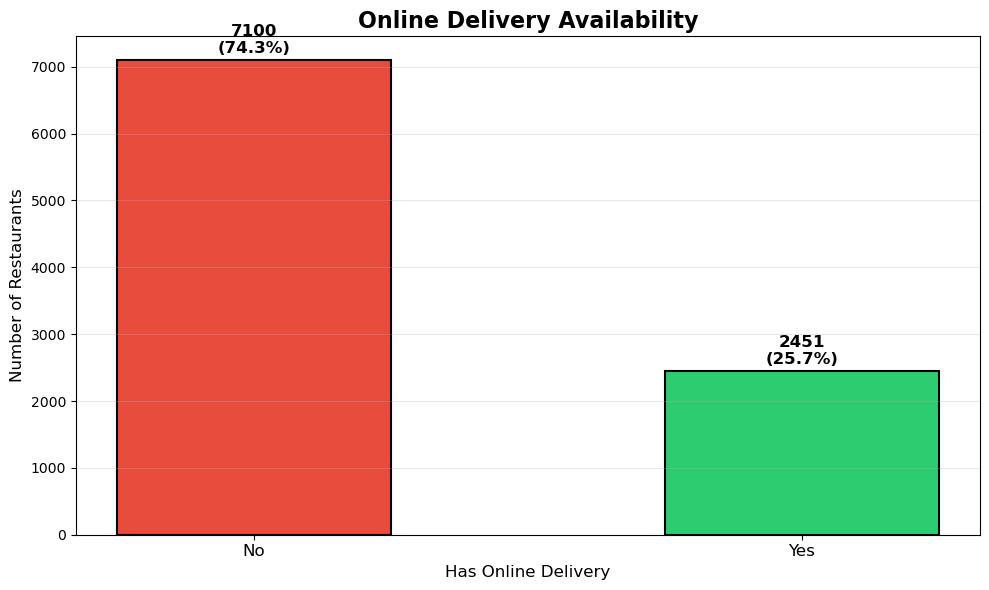

In [ ]:
# Bar chart - Count
plt.figure(figsize=(10, 6))

colors = ['#E74C3C', '#2ECC71']  # Red for No, Green for Yes
bar_labels = delivery_counts.index.tolist()

bars = plt.bar(bar_labels, delivery_counts.values,
               color=colors, edgecolor='black', linewidth=1.5, width=0.5)


for bar, count, status in zip(bars, delivery_counts.values, bar_labels):
    height = bar.get_height()
    pct = delivery_pct[status]
    plt.text(bar.get_x() + bar.get_width()/2, height + 100,
             f'{count}\n({pct:.1f}%)',
             ha='center', fontsize=12, fontweight='bold')

plt.title('Online Delivery Availability', fontsize=16, fontweight='bold')
plt.xlabel('Has Online Delivery', fontsize=12)
plt.ylabel('Number of Restaurants', fontsize=12)
plt.xticks(fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

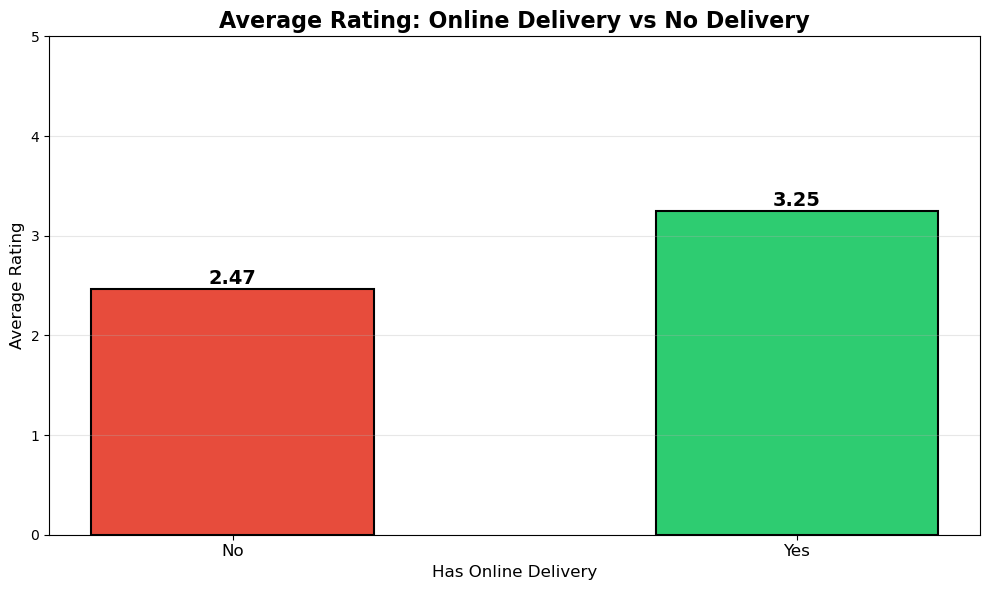

In [6]:
# Bar chart - Average Rating
plt.figure(figsize=(10, 6))

colors = ['#E74C3C', '#2ECC71']
bars = plt.bar(avg_ratings.index, avg_ratings.values,
               color=colors, edgecolor='black', linewidth=1.5, width=0.5)

# Rating labels
for bar, rating in zip(bars, avg_ratings.values):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.05,
             f'{rating:.2f}',
             ha='center', fontsize=14, fontweight='bold')

plt.title('Average Rating: Online Delivery vs No Delivery', 
          fontsize=16, fontweight='bold')
plt.xlabel('Has Online Delivery', fontsize=12)
plt.ylabel('Average Rating', fontsize=12)
plt.ylim(0, 5)
plt.xticks(fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

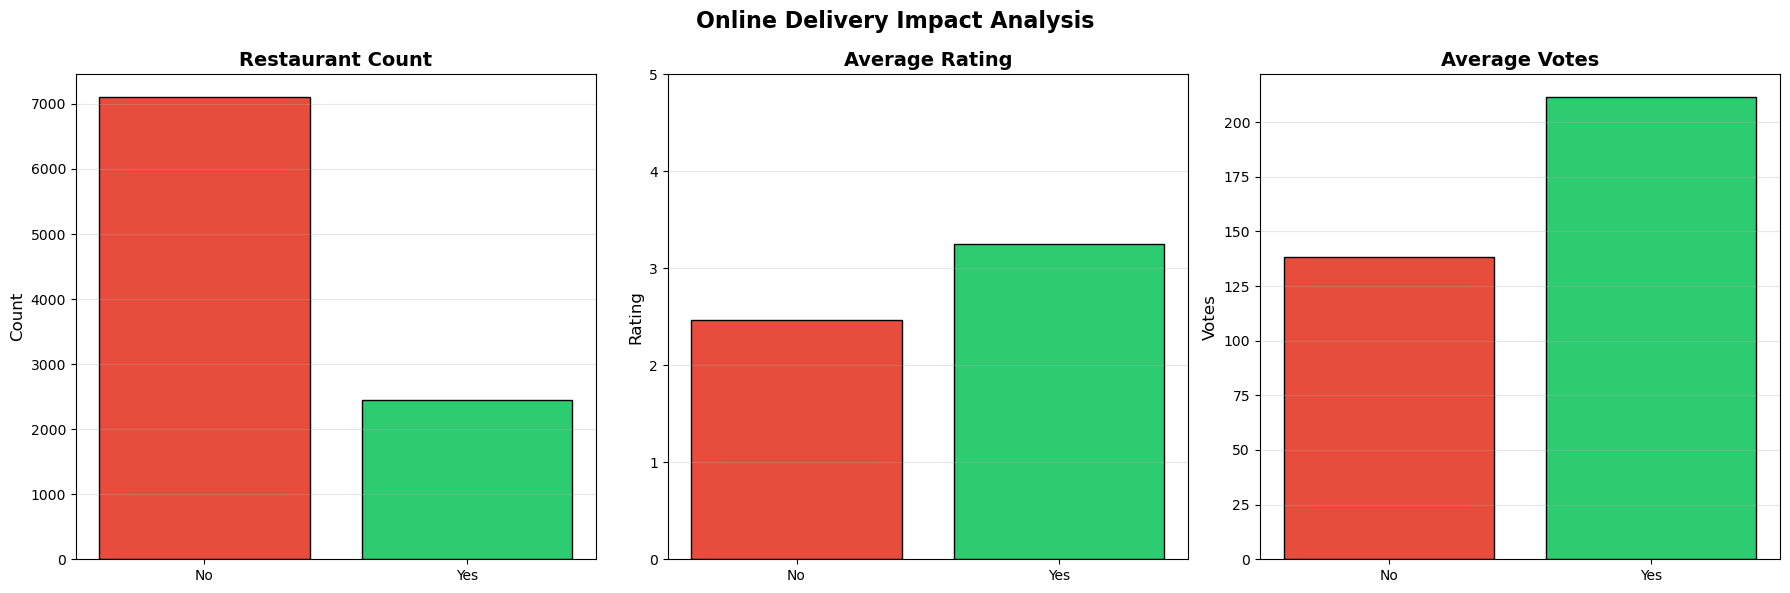

In [7]:
# Combined visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Chart 1: Count
axes[0].bar(delivery_counts.index, delivery_counts.values,
            color=['#E74C3C', '#2ECC71'], edgecolor='black')
axes[0].set_title('Restaurant Count', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Count', fontsize=12)
axes[0].grid(axis='y', alpha=0.3)

# Chart 2: Avg Rating
axes[1].bar(avg_ratings.index, avg_ratings.values,
            color=['#E74C3C', '#2ECC71'], edgecolor='black')
axes[1].set_title('Average Rating', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Rating', fontsize=12)
axes[1].set_ylim(0, 5)
axes[1].grid(axis='y', alpha=0.3)

# Chart 3: Avg Votes
axes[2].bar(avg_votes.index, avg_votes.values,
            color=['#E74C3C', '#2ECC71'], edgecolor='black')
axes[2].set_title('Average Votes', fontsize=14, fontweight='bold')
axes[2].set_ylabel('Votes', fontsize=12)
axes[2].grid(axis='y', alpha=0.3)

plt.suptitle('Online Delivery Impact Analysis', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

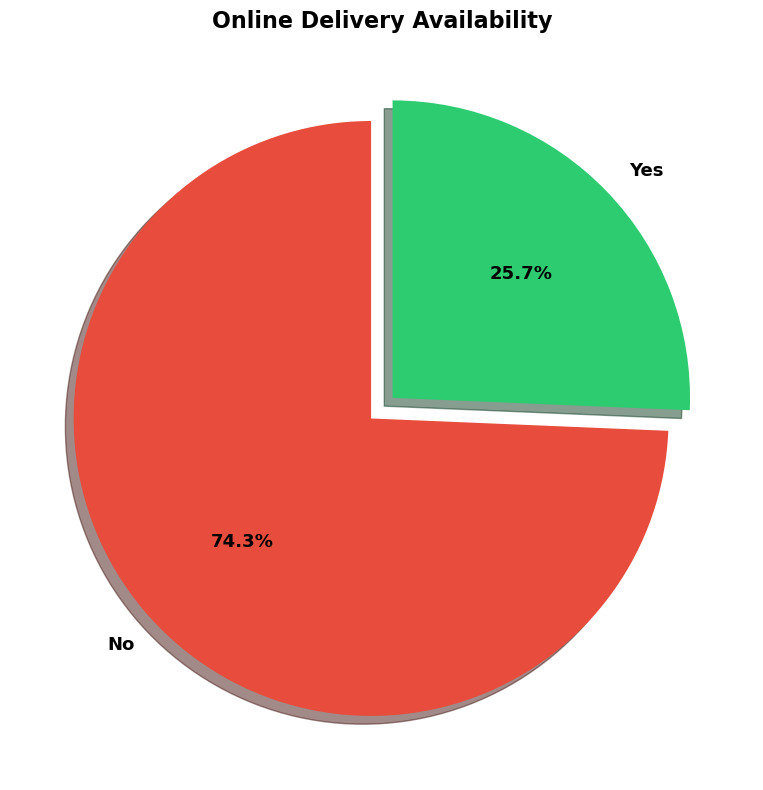

In [8]:
# Pie chart
plt.figure(figsize=(8, 8))

plt.pie(delivery_counts.values,
        labels=delivery_counts.index,
        autopct='%1.1f%%',
        colors=['#E74C3C', '#2ECC71'],
        startangle=90,
        explode=(0.05, 0.05),
        shadow=True,
        textprops={'fontsize': 13, 'fontweight': 'bold'})

plt.title('Online Delivery Availability', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

##  Insights

### 1. Online Delivery Availability
- **X%** of restaurants offer online delivery.
- **Y%** of restaurants do NOT offer online delivery.
- This shows online delivery is {common/rare} in the market.

### 2. Average Rating Comparison
- Restaurants WITH online delivery: **{Rating1}**
- Restaurants WITHOUT online delivery: **{Rating2}**
- Difference: **{+/- Diff}**

### 3. Key Observations
- {Yes/No} — Restaurants with online delivery tend to have {higher/lower} ratings.
- The average votes for restaurants with delivery is {X} vs {Y} for without.
- Online delivery presence suggests {larger/smaller} customer base.

### Conclusion
- Online delivery is a {significant/minor} part of the restaurant industry.
- Restaurants offering delivery tend to have {better/different} customer engagement.